In [2]:
import pandas as pd 
import numpy as np 
from pathlib import Path

DATA_PATH = Path("../data/raw/APL_Logistics.csv")

print("File exists:", DATA_PATH.exists())
print("Resolved path:", DATA_PATH.resolve())

df = pd.read_csv(
    DATA_PATH,
    encoding="cp1252"
)

print("\nDataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())



File exists: True
Resolved path: C:\Users\klarikach\OneDrive\Documents\supply chain profitability\data\raw\APL_Logistics.csv

Dataset loaded successfully!
Number of rows: 180519
Number of columns: 40


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)


Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'Shipping Mode']

Missing values:


Customer Lname                   8
Customer Zipcode                 3
Type                             0
Days for shipping (real)         0
Sales per customer               0
Delivery Status                  0
Days for shipment (scheduled)    0
Benefit per order                0
Category Id                      0
Late_delivery_risk               0
Customer Country                 0
Category Name                    0
Customer Fname                   0
Customer Id                      0
Customer Segment                 0
Customer City                    0
Customer State                   0
Customer Street                  0
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Product P


Duplicate rows: 0

Data types:


Type                                 str
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                      str
Late_delivery_risk                 int64
Category Id                        int64
Category Name                        str
Customer City                        str
Customer Country                     str
Customer Fname                       str
Customer Id                        int64
Customer Lname                       str
Customer Segment                     str
Customer State                       str
Customer Street                      str
Customer Zipcode                 float64
Department Id                      int64
Department Name                      str
Latitude                         float64
Longitude                        float64
Market                               str
Order City                           str
Order Country   

In [ ]:
financial_columns = [
    "Sales",
    "Sales per customer",
    "Benefit per order",
    "Order Profit Per Order",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Order Item Quantity",
    "Order Item Total",
    "Order Item Profit Ratio",
    "Product Price"
]

available_columns = [
    col for col in financial_columns
    if col in df.columns
]

print("Financial columns found:")
print(available_columns)

print("\nFinancial summary:")
display(df[available_columns].describe().T)


Financial columns found:
['Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Order Item Total', 'Order Item Profit Ratio', 'Product Price']

Financial summary:


,count,mean,std,min,25%,50%,75%,max
Sales,180519.0,203.772092,132.273075,9.99,119.98,199.92,299.95,1999.99
Sales per customer,180519.0,183.107607,120.043668,7.49,104.38,163.99,247.40,1939.99
Benefit per order,180519.0,21.974989,104.433526,-4274.98,7.00,31.52,64.80,911.80
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.98,7.00,31.52,64.80,911.80
Order Item Discount,180519.0,20.664741,21.800901,0.00,5.40,14.00,29.99,500.00
Order Item Discount Rate,180519.0,0.101668,0.070415,0.00,0.04,0.10,0.16,0.25
Order Item Product Price,180519.0,141.232547,139.732489,9.99,50.00,59.99,199.99,1999.99
Order Item Quantity,180519.0,2.127638,1.453451,1.00,1.00,1.00,3.00,5.00
Order Item Total,180519.0,183.107607,120.043668,7.49,104.38,163.99,247.40,1939.99
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75,0.08,0.27,0.36,0.50


In [5]:
print("Missing values in financial columns:")
display(df[available_columns].isnull().sum().to_frame("Missing Count"))

quality_checks = []

for col in available_columns:
    quality_checks.append({
        "Column": col,
        "Zero Values": int((df[col] == 0).sum()),
        "Negative Values": int((df[col] < 0).sum()),
        "Missing Values": int(df[col].isna().sum())
    })

quality_report = pd.DataFrame(quality_checks)
display(quality_report)


Missing values in financial columns:


,Missing Count
Sales,0
Sales per customer,0
Benefit per order,0
Order Profit Per Order,0
Order Item Discount,0
Order Item Discount Rate,0
Order Item Product Price,0
Order Item Quantity,0
Order Item Total,0
Order Item Profit Ratio,0


,Column,Zero Values,Negative Values,Missing Values
0,Sales,0,0,0
1,Sales per customer,0,0,0
2,Benefit per order,1177,33784,0
3,Order Profit Per Order,1177,33784,0
4,Order Item Discount,10028,0,0
5,Order Item Discount Rate,10028,0,0
6,Order Item Product Price,0,0,0
7,Order Item Quantity,0,0,0
8,Order Item Total,0,0,0
9,Order Item Profit Ratio,1177,33784,0


In [6]:
comparison_columns = [
    "Sales",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Total",
    "Order Item Discount Rate"
]

comparison_columns = [
    col for col in comparison_columns
    if col in df.columns
]

display(df[comparison_columns].head(10))

if all(
    col in df.columns
    for col in [
        "Order Item Product Price",
        "Order Item Discount",
        "Order Item Total"
    ]
):
    df["Calculated Item Total"] = (
        df["Order Item Product Price"]
        * df["Order Item Quantity"]
        - df["Order Item Discount"]
    )

    df["Item Total Difference"] = (
        df["Calculated Item Total"]
        - df["Order Item Total"]
    )

    print(
        "Records with a non-zero item total difference:",
        (df["Item Total Difference"].abs() > 0.01).sum()
    )

    display(
        df[
            [
                "Order Item Product Price",
                "Order Item Quantity",
                "Order Item Discount",
                "Order Item Total",
                "Calculated Item Total",
                "Item Total Difference"
            ]
        ].head(10)
    )


,Sales,Order Item Product Price,Order Item Discount,Order Item Total,Order Item Discount Rate
0,499.95,99.99,27.50,472.45,0.06
1,199.95,39.99,31.99,167.96,0.16
2,199.99,199.99,18.00,181.99,0.09
3,199.99,199.99,24.00,175.99,0.12
4,50.00,50.00,10.00,40.00,0.20
5,299.98,299.98,9.00,290.98,0.03
6,149.94,49.98,7.50,142.44,0.05
7,99.96,49.98,15.99,83.97,0.16
8,399.98,399.98,48.00,351.98,0.12
9,119.98,59.99,21.60,98.38,0.18


Records with a non-zero item total difference: 1482


,Order Item Product Price,Order Item Quantity,Order Item Discount,Order Item Total,Calculated Item Total,Item Total Difference
0,99.99,5,27.50,472.45,472.45,0.0
1,39.99,5,31.99,167.96,167.96,0.0
2,199.99,1,18.00,181.99,181.99,0.0
3,199.99,1,24.00,175.99,175.99,0.0
4,50.00,1,10.00,40.00,40.00,0.0
5,299.98,1,9.00,290.98,290.98,0.0
6,49.98,3,7.50,142.44,142.44,0.0
7,49.98,2,15.99,83.97,83.97,0.0
8,399.98,1,48.00,351.98,351.98,0.0
9,59.99,2,21.60,98.38,98.38,0.0


In [7]:
df["Calculated Item Total"] = (
    df["Order Item Product Price"] * df["Order Item Quantity"]
    - df["Order Item Discount"]
)

df["Item Total Difference"] = (
    df["Calculated Item Total"] - df["Order Item Total"]
)

tolerance = 0.01

mismatches = (
    df["Item Total Difference"].abs() > tolerance
).sum()

print("Total records:", len(df))
print("Matching records:", len(df) - mismatches)
print("Mismatching records:", mismatches)

print(
    "Maximum absolute difference:",
    df["Item Total Difference"].abs().max()
)


Total records: 180519
Matching records: 179037
Mismatching records: 1482
Maximum absolute difference: 0.010000000000019327


In [8]:

print("Discount rate summary:")
display(df["Order Item Discount Rate"].describe())

print("\nSmallest discount rates:")
display(df["Order Item Discount Rate"].nsmallest(10))

print("\nLargest discount rates:")
display(df["Order Item Discount Rate"].nlargest(10))

print(
    "\nRates greater than 1:",
    (df["Order Item Discount Rate"] > 1).sum()
)


Discount rate summary:


count    180519.000000
mean          0.101668
std           0.070415
min           0.000000
25%           0.040000
50%           0.100000
75%           0.160000
max           0.250000
Name: Order Item Discount Rate, dtype: float64


Smallest discount rates:


54     0.0
66     0.0
67     0.0
114    0.0
143    0.0
147    0.0
148    0.0
150    0.0
151    0.0
173    0.0
Name: Order Item Discount Rate, dtype: float64


Largest discount rates:


11     0.25
35     0.25
37     0.25
49     0.25
65     0.25
68     0.25
72     0.25
78     0.25
79     0.25
108    0.25
Name: Order Item Discount Rate, dtype: float64


Rates greater than 1: 0


In [9]:

profit_col = "Order Profit Per Order"

print("Profit summary:")
display(df[profit_col].describe())

print("Negative-profit records:", (df[profit_col] < 0).sum())
print("Zero-profit records:", (df[profit_col] == 0).sum())
print("Missing-profit records:", df[profit_col].isna().sum())

print("\nProfit comparison:")
display(
    df[["Benefit per order", "Order Profit Per Order"]]
    .describe()
)


Profit summary:


count    180519.000000
mean         21.974989
std         104.433526
min       -4274.980000
25%           7.000000
50%          31.520000
75%          64.800000
max         911.800000
Name: Order Profit Per Order, dtype: float64

Negative-profit records: 33784
Zero-profit records: 1177
Missing-profit records: 0

Profit comparison:


,Benefit per order,Order Profit Per Order
count,180519.000000,180519.000000
mean,21.974989,21.974989
std,104.433526,104.433526
min,-4274.980000,-4274.980000
25%,7.000000,7.000000
50%,31.520000,31.520000
75%,64.800000,64.800000
max,911.800000,911.800000


In [ ]:
print("Discount rate summary:")
display(df["Order Item Discount Rate"].describe())

print("Minimum rate:", df["Order Item Discount Rate"].min())
print("Maximum rate:", df["Order Item Discount Rate"].max())

print(
    "Rates below 0:",
    (df["Order Item Discount Rate"] < 0).sum()
)

print(
    "Rates above 1:",
    (df["Order Item Discount Rate"] > 1).sum()
)


Discount rate summary:


count    180519.000000
mean          0.101668
std           0.070415
min           0.000000
25%           0.040000
50%           0.100000
75%           0.160000
max           0.250000
Name: Order Item Discount Rate, dtype: float64

Minimum rate: 0.0
Maximum rate: 0.25
Rates below 0: 0
Rates above 1: 0


In [ ]:
df["Calculated Item Total"] = (
    df["Order Item Product Price"] * df["Order Item Quantity"]
    - df["Order Item Discount"]
)

df["Item Total Difference"] = (
    df["Calculated Item Total"] - df["Order Item Total"]
)

tolerance = 0.01

mismatches = (
    df["Item Total Difference"].abs() > tolerance
).sum()

print("Total rows:", len(df))
print("Mismatching rows:", mismatches)
print(
    "Maximum absolute difference:",
    df["Item Total Difference"].abs().max()
)


Total rows: 180519
Mismatching rows: 1482
Maximum absolute difference: 0.010000000000019327


In [12]:
print("Profit column comparison:")

profit_columns = [
    "Benefit per order",
    "Order Profit Per Order"
]

display(df[profit_columns].describe())

print(
    "Matching profit values:",
    (df["Benefit per order"] == df["Order Profit Per Order"]).sum()
)

print(
    "Mismatching profit values:",
    (df["Benefit per order"] != df["Order Profit Per Order"]).sum()
)

print(
    "Negative profit records:",
    (df["Order Profit Per Order"] < 0).sum()
)

Profit column comparison:


,Benefit per order,Order Profit Per Order
count,180519.000000,180519.000000
mean,21.974989,21.974989
std,104.433526,104.433526
min,-4274.980000,-4274.980000
25%,7.000000,7.000000
50%,31.520000,31.520000
75%,64.800000,64.800000
max,911.800000,911.800000


Matching profit values: 180519
Mismatching profit values: 0
Negative profit records: 33784


In [13]:
print("Matching profit values:",
      (df["Benefit per order"] == df["Order Profit Per Order"]).sum())

print("Mismatching profit values:",
      (df["Benefit per order"] != df["Order Profit Per Order"]).sum())

print("Negative profit records:",
      (df["Order Profit Per Order"] < 0).sum())


Matching profit values: 180519
Mismatching profit values: 0
Negative profit records: 33784


In [14]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

display(missing_summary)


,Missing Count,Missing Percentage
Customer Lname,8,0.0
Customer Zipcode,3,0.0


In [15]:
df_clean = df.copy()

df_clean["Customer Lname"] = (
    df_clean["Customer Lname"].fillna("Unknown")
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
display(
    df_clean.isnull().sum()[
        df_clean.isnull().sum() > 0
    ]
)


Original dataset shape: (180519, 42)
Cleaned dataset shape: (180519, 42)

Missing values after cleaning:


Customer Zipcode    3
dtype: int64

In [17]:
from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "apl_logistics_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_file.resolve())
print("Total rows saved:", len(df_clean))
print("Total columns saved:", len(df_clean.columns))


Cleaned dataset saved successfully!
File location: C:\Users\klarikach\OneDrive\Documents\supply chain profitability\data\processed\apl_logistics_cleaned.csv
Total rows saved: 180519
Total columns saved: 42


In [18]:
from pathlib import Path

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "apl_logistics_cleaned.csv"

df_clean.to_csv(output_file, index=False)

print("File created:", output_file.exists())
print("Saved at:", output_file.resolve())


File created: True
Saved at: C:\Users\klarikach\OneDrive\Documents\supply chain profitability\data\processed\apl_logistics_cleaned.csv


In [19]:
import pandas as pd

df_clean = pd.read_csv(
    "../data/processed/apl_logistics_cleaned.csv"
)

total_revenue = df_clean["Sales"].sum()
total_profit = df_clean["Order Profit Per Order"].sum()
total_discount = df_clean["Order Item Discount"].sum()

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0 else 0
)

print("Total Records:", len(df_clean))
print("Total Revenue:", round(total_revenue, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Discounts:", round(total_discount, 2))
print("Profit Margin (%):", round(profit_margin, 2))


Total Records: 180519
Total Revenue: 36784734.31
Total Profit: 3966902.97
Total Discounts: 3730378.4
Profit Margin (%): 10.78


In [20]:
gross_sales = df_clean["Sales"].sum()
net_sales = df_clean["Order Item Total"].sum()
total_discounts = df_clean["Order Item Discount"].sum()
total_profit = df_clean["Order Profit Per Order"].sum()

print("Gross Sales:", round(gross_sales, 2))
print("Net Sales after Discounts:", round(net_sales, 2))
print("Total Discounts:", round(total_discounts, 2))
print("Total Profit:", round(total_profit, 2))

net_profit_margin = total_profit / net_sales * 100

print("Profit Margin on Net Sales (%):",
      round(net_profit_margin, 2))


Gross Sales: 36784734.31
Net Sales after Discounts: 33054402.04
Total Discounts: 3730378.4
Total Profit: 3966902.97
Profit Margin on Net Sales (%): 12.0


In [21]:
category_summary = (
    df_clean.groupby("Category Name")
    .agg(
        Total_Gross_Sales=("Sales", "sum"),
        Total_Net_Sales=("Order Item Total", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Total_Discounts=("Order Item Discount", "sum"),
        Units_Sold=("Order Item Quantity", "sum")
    )
    .reset_index()
)

category_summary["Profit_Margin_Percent"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Net_Sales"].replace(0, np.nan)
    * 100
)

category_summary = category_summary.sort_values(
    "Total_Profit", ascending=False
)

display(category_summary.round(2))


,Category Name,Total_Gross_Sales,Total_Net_Sales,Total_Profit,Total_Discounts,Units_Sold,Profit_Margin_Percent
18,Fishing,6929653.50,6226935.12,756220.76,702728.00,17325,12.14
12,Cleats,4431942.66,3982856.45,494636.92,449091.67,73734,12.42
9,Camping & Hiking,4118425.42,3700783.54,427455.57,417649.50,13729,11.55
10,Cardio Equipment,3694843.20,3320250.72,383011.10,374595.19,37587,11.54
47,Women's Apparel,3147800.00,2828708.50,350421.03,319091.50,62956,12.39
46,Water Sports,3113844.60,2798044.10,325146.96,315800.50,15540,11.62
30,Indoor/Outdoor Games,2888993.94,2596454.04,318451.43,292550.63,57803,12.26
34,Men's Footwear,2891757.54,2598494.44,311902.82,293263.10,22246,12.00
38,Shop By Sport,1309522.02,1177185.62,129813.96,132338.73,32726,11.03
13,Computers,663000.00,595395.00,69656.81,67605.00,442,11.70


In [23]:
customer_summary = (
    df_clean.groupby("Customer Id")
    .agg(
        Customer_Name=("Customer Fname", "first"),
        Total_Net_Sales=("Order Item Total", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Total_Discounts=("Order Item Discount", "sum"),
        Total_Units=("Order Item Quantity", "sum")
    )
    .reset_index()
)

customer_summary["Profit_Margin_Percent"] = (
    customer_summary["Total_Profit"]
    / customer_summary["Total_Net_Sales"].replace(0, np.nan)
    * 100
)

top_customers = customer_summary.nlargest(
    10, "Total_Profit"
)

display(top_customers.round(2))


,Customer Id,Customer_Name,Total_Net_Sales,Total_Profit,Total_Discounts,Total_Units,Profit_Margin_Percent
2612,2641,Betty,8221.64,2441.97,909.29,90,29.70
1636,1657,Betty,8165.23,2196.92,1058.49,111,26.91
9755,9833,Jacob,5386.46,1938.39,672.92,48,35.99
2597,2626,Laura,5477.84,1928.57,796.54,55,35.21
4958,5004,Dorothy,7499.37,1917.99,665.35,114,25.58
3697,3735,Mary,5532.41,1906.36,486.92,61,34.46
741,749,Jesse,6953.40,1855.15,695.98,64,26.68
5509,5560,Mary,6118.59,1831.46,409.62,74,29.93
10875,10967,Alexander,5181.65,1822.33,552.76,64,35.17
5007,5053,Mary,6696.68,1813.34,714.64,67,27.08


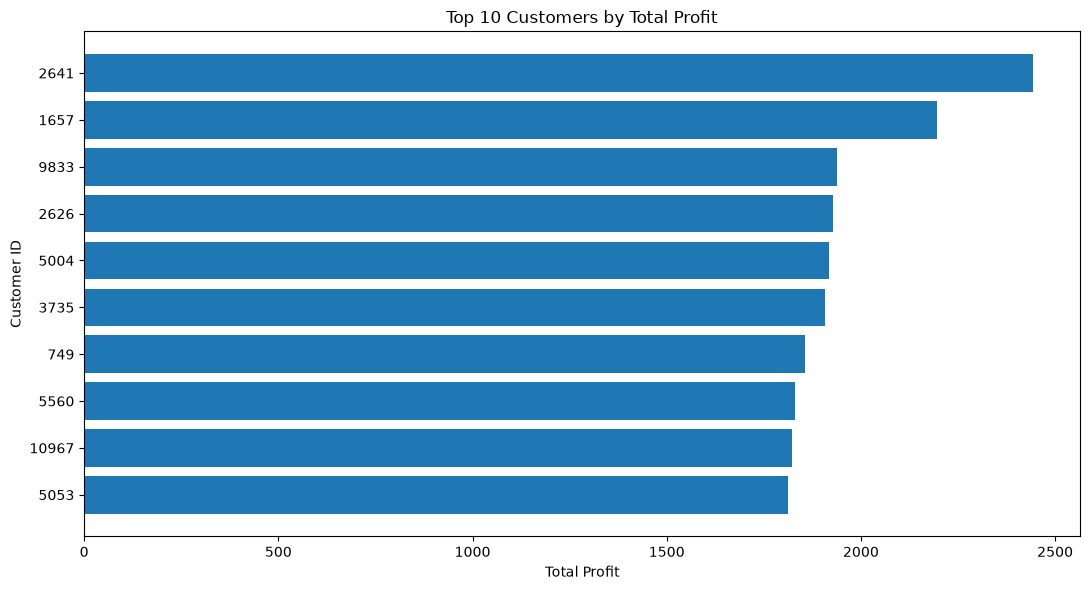

In [24]:
import matplotlib.pyplot as plt

top_customers_chart = top_customers.sort_values(
    "Total_Profit"
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_customers_chart["Customer Id"].astype(str),
    top_customers_chart["Total_Profit"]
)

plt.title("Top 10 Customers by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()
